# Descriptive statistics on US PCE

In [1]:
# Librairies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from fismi import sdxData as sdx
from fismi import utils
import matplotlib.dates as mdates
from fismi import sdxData
import json

np.set_printoptions(suppress=True, precision=4)
plt.rcParams["figure.figsize"] = (9, 5)

In [2]:
def addHawkishRegimes(ax, starts, ends, color="pink", alpha=0.12):
    
    for start, end in zip(starts, ends):

        # Shaded regime
        ax.axvspan(
            start,
            end,
            color=color,
            alpha=alpha
        )

        # Regime boundaries
        ax.axvline(
            start,
            color=color,
            linewidth=0.8,
            alpha=0.7
        )

        ax.axvline(
            end,
            color=color,
            linewidth=0.8,
            alpha=0.7
        )

In [3]:
# Add FOMC dates on charts
def addLinesFomc(ax, fomc, col):
    
    # Convert FOMC dates to datetime
    fomc = pd.to_datetime(fomc, errors="coerce").dropna()

    # Get chart date boundaries
    xmin, xmax = ax.get_xlim()
    
    xmin = pd.to_datetime(mdates.num2date(xmin)).tz_localize(None)
    xmax = pd.to_datetime(mdates.num2date(xmax)).tz_localize(None)

    # Keep only FOMC dates within chart
    fomc = fomc[(fomc >= xmin) & (fomc <= xmax)]

    # Add vertical lines
    for date in fomc:
        ax.axvline(
            x=date,
            linestyle="--",
            color=col,
            alpha=0.5,
            linewidth=0.8,
            zorder=0
        )

## Weights per components of the PCE

In [4]:
# Unchained other items 
niv = "2"
dfW = pd.read_parquet(f"input/USnormedWeightsLvl{niv}.parquet") 

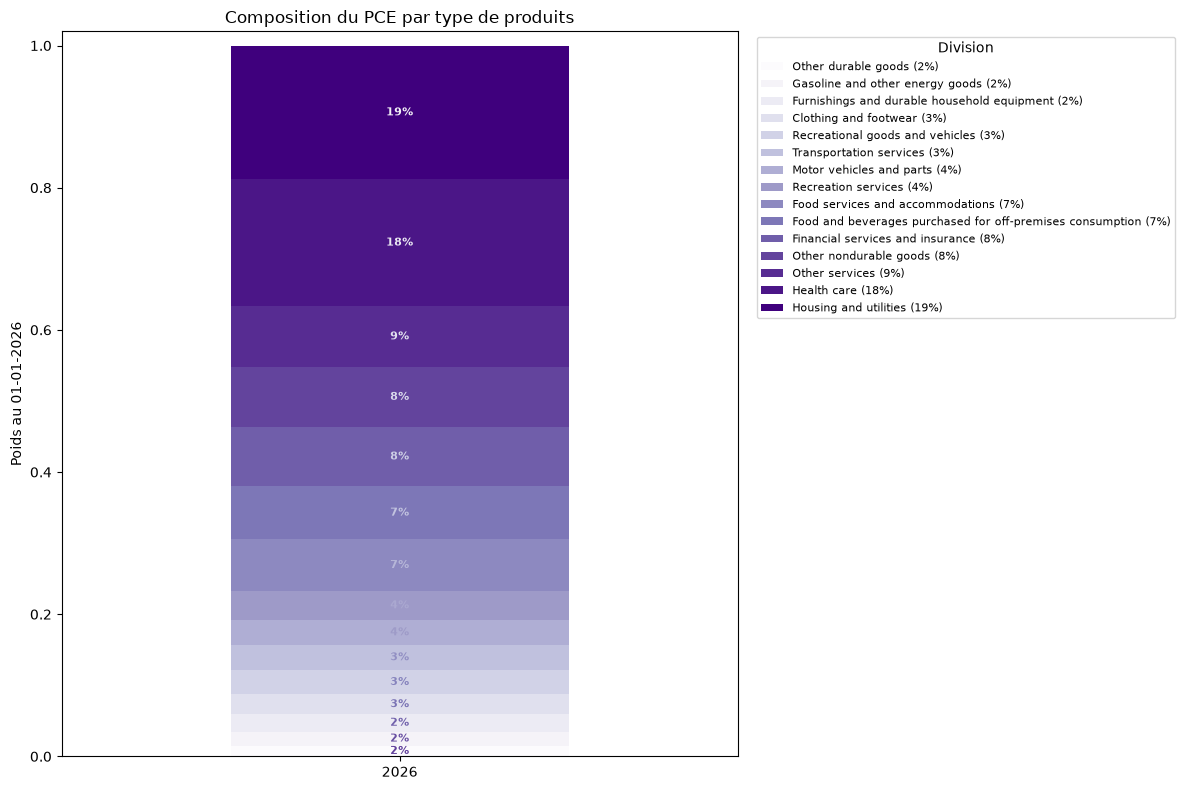

In [5]:
utils.plotConsumptionShares(dfW, colors="Purples", yyyy=2026, title="Composition du PCE par type de produits")

## Inflation YoY and MoM over time, with Fed hikes and cuts


In [6]:
# Import data
niv = '4'
dfICP = pd.read_parquet(f"input/USItemsLvl{niv}.parquet")

# We compute headline inflation (PCE variation over a 12-month period)
YoY = (np.log(dfICP["Personal consumption expenditures"]).diff(12)[12:]*100).rename("YoY")  # Inflation headline annuelle glissante
MoM = (np.log(dfICP["Personal consumption expenditures"]).diff(1)[12:]*100).rename("MoM")

In [7]:
# Import ISM, S+, S- for the US
Ismi = pd.read_excel("output/USIsmiOutput.xlsx")
Ismi = Ismi.set_index("TIME_PERIOD", drop=True)

In [8]:
# Import Rho
RhoDf = pd.read_excel("output/USRhoFullEstimates.xlsx")
RhoDf = RhoDf.set_index("TIME_PERIOD", drop=True)

In [9]:
# Get 5y5y Inflation Expectations
# Query data ; API key
with open('/Users/lea_gosselin/.openbb_platform/user_settings.json', 'r') as file:
    keys = json.load(file)
    
key=keys["credentials"].get("fred_api_key") 

tick = "T5YIFR"
url = f"https://api.stlouisfed.org/fred/series/observations?series_id={tick}&api_key={key}&file_type=json"
df = sdxData.queryFredData(url)
df.columns = ["5y5yExpectations"]

In [10]:
# Merge
df = pd.concat(
    [YoY, MoM, Ismi, RhoDf, df],
    axis=1,
    join="outer"
).sort_index().dropna()

df.index = df.index.to_period("M").to_timestamp("M")
df

,YoY,MoM,ISMI+,ISMI-,ISMIndex,Personal consumption expenditures,Rho,5y5yExpectations
2003-04-30,1.969180,-0.169974,0.191493,0.236966,-0.045473,-0.169974,0.372263,2.00
2003-05-31,1.788714,-0.114767,0.227395,0.249054,-0.021659,-0.114767,0.428140,2.20
2003-07-31,1.845600,0.293429,0.077273,0.139757,-0.062484,0.293429,0.414124,1.83
2003-08-31,1.986846,0.337407,0.107077,0.113277,-0.006200,0.337407,0.423816,2.33
2003-10-31,1.949093,0.012767,0.158072,0.088693,0.069379,0.012767,0.414516,2.16
...,...,...,...,...,...,...,...,...
2025-12-31,2.739292,0.319688,0.104582,0.091596,0.012986,0.319688,0.589100,2.17
2026-04-30,3.511564,0.434855,0.122158,0.086773,0.035386,0.434855,0.657323,2.07
2026-05-31,3.752056,0.434496,0.186366,0.122225,0.064141,0.434496,0.672799,2.27
2026-06-30,3.394732,-0.102917,0.069004,0.132141,-0.063137,-0.102917,0.591427,2.26


In [11]:
# Get FOMC dates
fomcDates = pd.read_excel("fomcDatesHistory.xlsx")
fomcDates = fomcDates.set_index("date",drop=True)
fomcDatesRes = fomcDates[fomcDates.index > df.index[0]]

In [12]:
# Get FED hawkish regimes
mpRegimes = pd.read_excel("MonetaryRegimes.xlsx").iloc[:, :2]
mpRegimes.columns = ["Date", "MP_Factor_US"]
mpRegimes["Date"] = pd.to_datetime(mpRegimes["Date"])
mpRegimes = mpRegimes.set_index("Date")

In [13]:
# Find beginning / end of Hawhkish cycle
mpRegimes["Month"] = mpRegimes.index.to_period("M").to_timestamp("M")

hawkishMonthly = pd.DataFrame(
    mpRegimes
    .groupby("Month")["MP_Factor_US"]
    .apply(lambda x: (x > 0.5).any())
    .astype(int)
)

# Resize on DF index
hawkishMonthly = hawkishMonthly.iloc[hawkishMonthly.index.get_loc(df.index[0]):]

hawkishMonthly["StartDate"] = pd.NaT
hawkishMonthly["EndDate"] = pd.NaT

# Beginning of hawkish regime: 0 -> 1
startMask = (
    (hawkishMonthly["MP_Factor_US"] == 1) &
    (hawkishMonthly["MP_Factor_US"].shift(1, fill_value=0) == 0)
)

# End of hawkish regime: 1 -> 0
endMask = (
    (hawkishMonthly["MP_Factor_US"] == 1) &
    (hawkishMonthly["MP_Factor_US"].shift(-1, fill_value=0) == 0)
)

hawkishMonthly.loc[startMask, "StartDate"] = hawkishMonthly.index[startMask]
hawkishMonthly.loc[endMask, "EndDate"] = hawkishMonthly.index[endMask]

# Start / Ends
starts = hawkishMonthly.index[startMask]
ends   = hawkishMonthly.index[endMask]

hawkishPeriods = pd.DataFrame({
    "StartDate": starts,
    "EndDate": ends
})

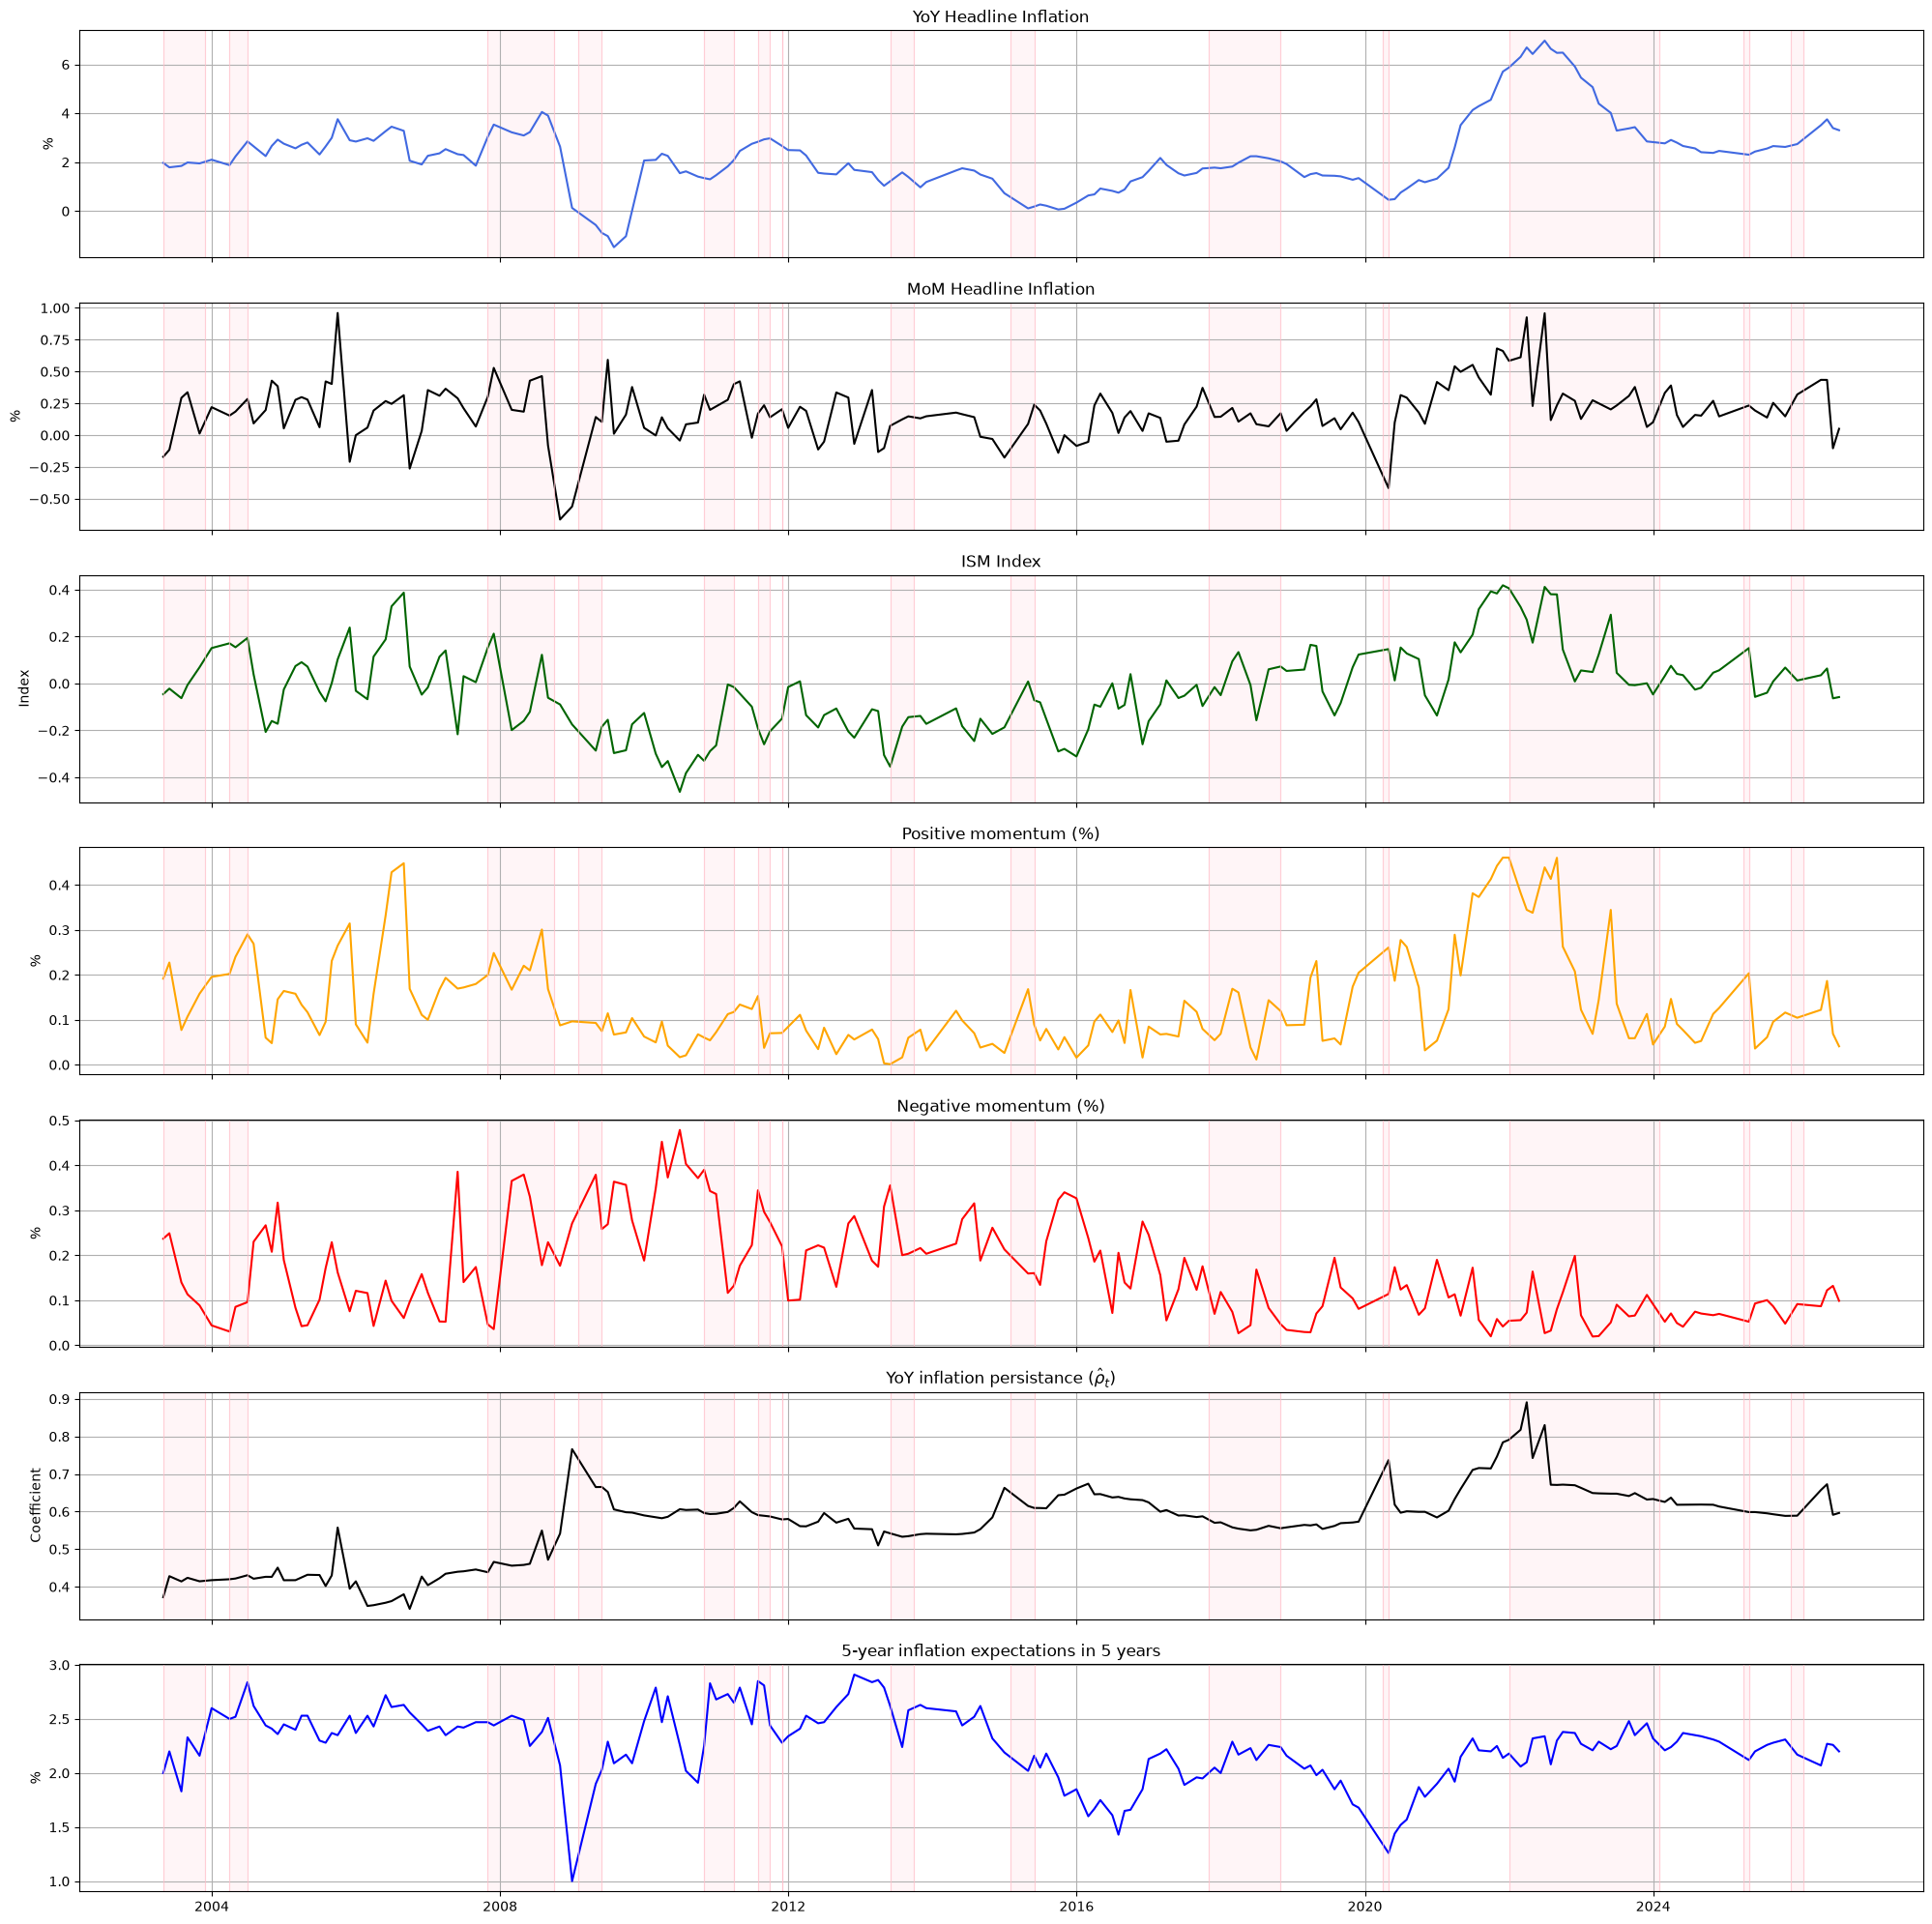

In [14]:
# Plot Yoy and Mom series, ISM, S+, S-, Rho...
xAxis = df.index
fig, axes = plt.subplots(
    7, 1,
    figsize=(20, 20),
    sharex=True # Align panel together
)

ax1, ax2, ax3, ax4, ax5, ax6, ax7 = axes

ax1.plot(xAxis, df.YoY, color='royalblue')
ax1.set_title('YoY Headline Inflation')
ax1.set_ylabel('%')
ax1.grid()

ax2.plot(xAxis, df.MoM, color='black')
ax2.set_title('MoM Headline Inflation')
ax2.set_ylabel('%')
ax2.grid()

ax3.plot(xAxis, df["ISMIndex"], color='darkgreen')
ax3.set_title('ISM Index')
ax3.set_ylabel('Index')
ax3.grid()

ax4.plot(xAxis, df["ISMI+"], color='orange')
ax4.set_title('Positive momentum (%)')
ax4.set_ylabel('%')
ax4.grid()

ax5.plot(xAxis, df["ISMI-"], color='red')
ax5.set_title('Negative momentum (%)')
ax5.set_ylabel('%')
ax5.grid()

ax6.plot(xAxis, df["Rho"], color='black')
ax6.set_title(r'YoY inflation persistance ($\hat \rho_t$)')
ax6.set_ylabel('Coefficient')
ax6.grid()

ax7.plot(xAxis, df["5y5yExpectations"], color='blue')
ax7.set_title("5-year inflation expectations in 5 years")
ax7.set_ylabel('%')
ax7.grid()

# Fed Hawkish
for ax in axes:
    addHawkishRegimes(
        ax,
        starts,
        ends,
        color="pink",
        alpha=0.15
    )

# # Add fomc dates (Hike, pink)
# for ax in axes:
#     addLinesFomc(ax, fomcDatesRes.Hike, "pink")
    
# # Add fomc dates (Cut, green)
# for ax in axes:
#     addLinesFomc(ax, fomcDatesRes.Cut, "grey")

plt.tight_layout()
plt.show()